# 07: Expected Loss Calculation and Portfolio Analysis

This notebook computes the Expected Loss (EL) for every loan in the portfolio and validates the results through economic coherence checks and segment-level analysis. Comparisons with observed losses use matured loans only, the loans whose outcome is complete (see `01_data_diagnosis`); for younger loans the observed losses are still accruing.

$$
\text{EL} = PD \times \frac{LGD}{100} \times EAD
$$

**Input:** `data/processed/checkpoint_df_master_with_PD_LGD.pkl`  
**Output:** `data/processed/portfolio_with_EL.pkl`

## Libraries

In [1]:
# Run from the repository root so that data/, models/ and src/ resolve the same way
# whether the notebook is opened from the root or from production_notebooks/.
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "production_notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

from sklearn.model_selection import train_test_split

from readme_figures import plot_el_by_quartile, plot_key_metrics, plot_pipeline, interest_rate_ranges

## 1. Load Checkpoint

In [3]:
with open("data/processed/checkpoint_df_master_with_PD_LGD.pkl", "rb") as f:
    data = pickle.load(f)
df_master_features = data["df_master_features"]

print(f"Portfolio shape: {df_master_features.shape}")
print(f"Columns with model outputs: {[c for c in df_master_features.columns if c in ['PD', 'LGD', 'EAD']]}")

Portfolio shape: (2139643, 57)
Columns with model outputs: ['EAD', 'PD', 'LGD']


## 2. Expected Loss Calculation

LGD is divided by 100 to convert from percentage scale (0-100) to proportion (0-1), consistent with `Target_Variable_Loss = 100 * net_loss / EAD` (see `01_data_diagnosis`). EL is a lifetime figure: the loss expected over the life of each loan, not an annual rate.

In [4]:
df_master_features["EL"] = (
    df_master_features["PD"] *
    (df_master_features["LGD"] / 100) *
    df_master_features["EAD"]
)

print(f"EL computed for {len(df_master_features):,} loans")
print(f"Total EL       : {df_master_features['EL'].sum():,.0f}")
print(f"Mean EL / loan : {df_master_features['EL'].mean():,.2f}")

EL computed for 2,139,643 loans
Total EL       : 3,221,170,690
Mean EL / loan : 1,505.47


## 3. Validation

### 3.1 EL vs Observed Loss (matured loans)

For a matured loan the lifetime outcome is known, so its EL can be compared with the loss it actually produced. Loans that have not reached maturity are left out of this comparison: their observed losses are incomplete.

In [5]:
mask_default = df_master_features["Target_Variable_Default"] == 1
matured = df_master_features["is_matured"] == 1

# Observed loss: realised LGD x EAD on the loans that defaulted
observed_loss_dev = (
    df_master_features.loc[matured & mask_default, "EAD"] *
    df_master_features.loc[matured & mask_default, "Target_Variable_Loss"] / 100
).sum()
expected_loss_dev = df_master_features.loc[matured, "EL"].sum()
expected_loss = df_master_features["EL"].sum()      # whole portfolio, used below

print(f"Matured loans                    : {matured.sum():,}")
print(f"Observed loss (matured, defaulted): {observed_loss_dev:,.0f}")
print(f"Expected loss (matured)          : {expected_loss_dev:,.0f}")
print(f"EL / observed loss (matured)     : {expected_loss_dev / observed_loss_dev:.4f}")

Matured loans                    : 676,113
Observed loss (matured, defaulted): 700,895,593
Expected loss (matured)          : 696,244,482
EL / observed loss (matured)     : 0.9934


### 3.1b Out-of-sample check on the test loans

The comparison above covers all matured loans, including those the models were trained on, so it is partly in-sample. The same comparison restricted to the PD test split (matured loans unseen by the PD model and its calibrator) is the honest version.

In [6]:
test = df_master_features["split_PD"] == "test"

observed_loss_test = (
    df_master_features.loc[test & mask_default, "EAD"] *
    df_master_features.loc[test & mask_default, "Target_Variable_Loss"] / 100
).sum()
expected_loss_test = df_master_features.loc[test, "EL"].sum()

print(f"Test loans                   : {test.sum():,}")
print(f"Observed loss (test, default): {observed_loss_test:,.0f}")
print(f"Expected loss (test)         : {expected_loss_test:,.0f}")
print(f"EL / observed loss (test)    : {expected_loss_test / observed_loss_test:.4f}")

Test loans                   : 135,223
Observed loss (test, default): 140,684,130
Expected loss (test)         : 138,943,183
EL / observed loss (test)    : 0.9876


### 3.2 EL Decomposition by Population (matured loans)

In [7]:
el_default    = df_master_features.loc[matured & mask_default,  "EL"].sum()
el_no_default = df_master_features.loc[matured & ~mask_default, "EL"].sum()

print(f"EL defaulted loans    : {el_default:,.0f}")
print(f"EL non-defaulted loans: {el_no_default:,.0f}")
print(f"% EL from non-defaulted: {el_no_default / expected_loss_dev * 100:.2f}%")

EL defaulted loans    : 148,255,744
EL non-defaulted loans: 547,988,738
% EL from non-defaulted: 78.71%


### 3.3 EL Rate

The portfolio EL rate covers every loan. It is also shown separately for matured loans and for loans still running.

In [8]:
total_ead = df_master_features["EAD"].sum()
el_rate   = expected_loss / total_ead * 100

print(f"Total EAD (portfolio): {total_ead:,.0f}")
print(f"Total EL (portfolio) : {expected_loss:,.0f}")
print(f"EL rate (portfolio)  : {el_rate:.2f}%")

by_maturity = df_master_features.groupby("is_matured").agg(
    loans=("EAD", "size"), EAD=("EAD", "sum"), EL=("EL", "sum")
)
by_maturity["EL_rate_pct"] = by_maturity["EL"] / by_maturity["EAD"] * 100
by_maturity = by_maturity.drop(columns="EL").rename(index={0: "not matured", 1: "matured"})
print(by_maturity.round(2))

Total EAD (portfolio): 31,628,836,375
Total EL (portfolio) : 3,221,170,690
EL rate (portfolio)  : 10.18%


               loans          EAD  EL_rate_pct
is_matured                                    
not matured  1463530  22800332425        11.07
matured       676113   8828503950         7.89


### 3.4 EL Distribution

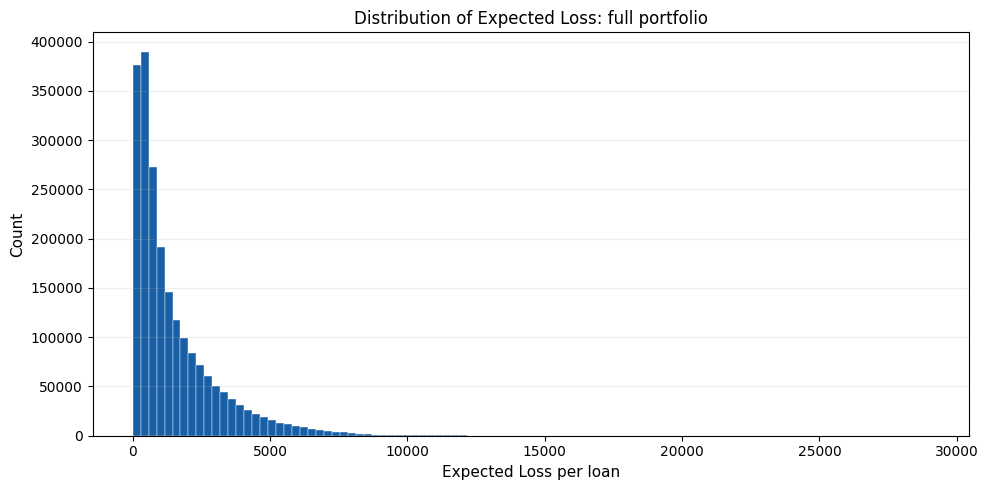

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_master_features["EL"], bins=100, color="#185FA5", edgecolor="white", linewidth=0.3)
ax.set_xlabel("Expected Loss per loan", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_title("Distribution of Expected Loss: full portfolio", fontsize=12)
ax.grid(True, alpha=0.2, axis="y")
plt.tight_layout()
plt.show()

## 4. Portfolio Analysis by Segment

### 4.1 EL Rate by Loan Term

In [10]:
sums_by_term = df_master_features.groupby("loan_term_months")[["EL", "EAD"]].sum()
el_by_term = (sums_by_term["EL"] / sums_by_term["EAD"] * 100).round(2)
print(el_by_term)

# 60-month loans should show higher EL rate than 36-month loans
assert el_by_term[60] > el_by_term[36], "EL rate ordering violated: 60m should exceed 36m"

loan_term_months
36     7.13
60    15.01
dtype: float64


### 4.2 EL Rate by Interest Rate Quartile

In [11]:
df_master_features["interest_rate_q"] = pd.qcut(
    df_master_features["interest_rate"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
)

sums_by_rate = df_master_features.groupby("interest_rate_q", observed=True)[["EL", "EAD"]].sum()
el_by_rate = (sums_by_rate["EL"] / sums_by_rate["EAD"] * 100).round(2)
print(el_by_rate)

# Q4 (highest rates) must have higher EL rate than Q1 (lowest rates)
assert el_by_rate["Q4"] > el_by_rate["Q1"], "EL rate ordering violated: Q4 should exceed Q1"

interest_rate_q
Q1     3.07
Q2     7.15
Q3    11.18
Q4    18.20
dtype: float64


Saved assets\el_by_quartile.png


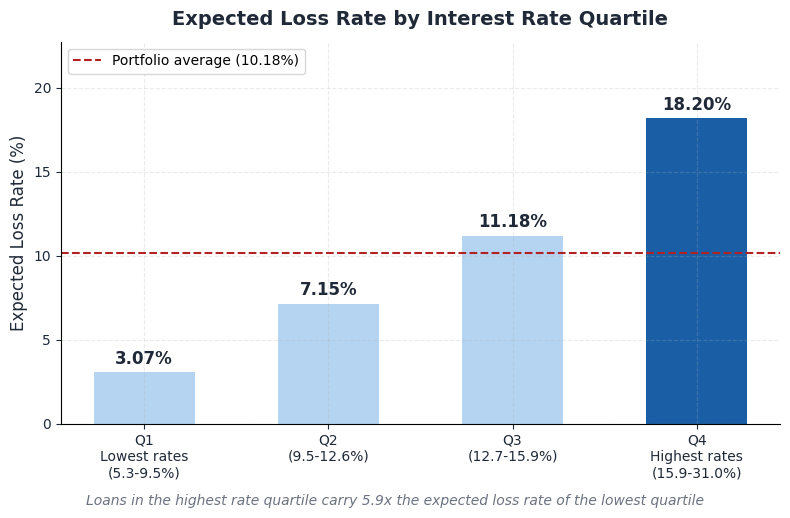

In [12]:
# EL rate by interest rate quartile (also saved for the README)
plot_el_by_quartile(el_by_rate, el_rate, interest_rate_ranges(df_master_features))
plt.show()

### 4.3 PD Calibration Check by Segment (matured loans)

Observed default rates are only complete for matured loans, so the check is restricted to them.

In [13]:
# PD mean vs observed default rate per interest rate quartile, matured loans
calibration_check = df_master_features[matured].groupby("interest_rate_q", observed=True).agg(
    pd_mean=("PD", "mean"),
    default_rate=("Target_Variable_Default", "mean")
).round(4)

print(calibration_check)

                 pd_mean  default_rate
interest_rate_q                       
Q1                0.0616        0.0646
Q2                0.1236        0.1241
Q3                0.1814        0.1793
Q4                0.2607        0.2604


### 4.4 PD Calibration by Term and Vintage

The quartile check above pools both terms and every vintage. The table below splits the matured loans by term and issue year, the dimensions along which the portfolio changes over time (the share of 60-month loans, Lending Club's underwriting standards). For loans not yet matured the observed default rate is only a lower bound: those loans still have time left to default.

In [14]:
calib_vintage = df_master_features.groupby(["loan_term_months", "issue_date_year", "is_matured"]).agg(
    loans=("PD", "size"), pd_mean=("PD", "mean"), default_rate=("Target_Variable_Default", "mean"),
)
calib_vintage["gap_pp"] = 100 * (calib_vintage["default_rate"] - calib_vintage["pd_mean"])
calib_vintage = calib_vintage[calib_vintage["loans"] >= 1_000].round(3)

print("Matured loans (outcome complete):")
print(calib_vintage.xs(1, level="is_matured").to_string())
print("\nNot matured (observed default rate so far is a lower bound):")
print(calib_vintage.xs(0, level="is_matured").to_string())

# Same check on the PD test split only (out of sample), by term
test_by_term = df_master_features[test].groupby("loan_term_months").agg(
    loans=("PD", "size"), pd_mean=("PD", "mean"), default_rate=("Target_Variable_Default", "mean"))
print("\nPD test split by term:")
print(test_by_term.round(4).to_string())

Matured loans (outcome complete):
                                   loans  pd_mean  default_rate  gap_pp
loan_term_months issue_date_year                                       
36               2008               2393    0.165         0.207   4.203
                 2009               5279    0.139         0.137  -0.205
                 2010               9156    0.126         0.109  -1.722
                 2011              14101    0.105         0.106   0.106
                 2012              43464    0.129         0.136   0.654
                 2013             100411    0.140         0.123  -1.659
                 2014             162543    0.144         0.137  -0.715
                 2015             282908    0.139         0.149   0.976
60               2010               3381    0.219         0.224   0.453
                 2011               7620    0.232         0.236   0.384
                 2012               9897    0.262         0.277   1.535
                 2013         


PD test split by term:
                   loans  pd_mean  default_rate
loan_term_months                               
36                124139   0.1393        0.1394
60                 11084   0.2517        0.2533


**Reading.** On matured loans the PD tracks the observed default rate within 2 points in every vintage from 2009 on, for both terms (2008, 2,400 loans issued during the financial crisis, defaulted 4 points above its prediction), and the test split is calibrated by term (36 months: 0.139 against 0.139; 60 months: 0.252 against 0.253). The first run of the pipeline, without `loan_term_months` among the PD features, missed the 60-month loans by 4 to 6 points in every vintage; adding the term closed that gap (see `02_feature_selection`).

For the loans still running, the observed default rate so far is a lower bound. The 60-month loans of 2014 and 2015, close to maturity, have already reached their predicted PD (0.263 against 0.260 and 0.253 against 0.252), and the 36-month loans of 2016, with up to a year left, are already at 0.151 against a predicted 0.153. These vintages will end somewhat above their prediction: Lending Club's 2015-2016 loans performed worse than earlier ones with the same application profile, a drift that a model trained on older vintages cannot see. The Expected Loss of the running loans is therefore more likely understated than overstated.

### 4.5 Why the Loans Still Running Carry a Higher EL Rate

The loans not yet matured have a higher EL rate than the matured ones (section 3.3). The comparison below separates composition (more 60-month loans and weaker grades among the recent vintages) from a difference that survives within the same term and grade.

In [15]:
df_master_features["grade_letter"] = df_master_features["grade"].astype(str).str[0]

mix = df_master_features.groupby("is_matured").agg(
    loans=("EAD", "size"),
    share_60m=("loan_term_months", lambda s: (s == 60).mean()),
    mean_interest_rate=("interest_rate", "mean"),
    pd_mean=("PD", "mean"),
    lgd_mean=("LGD", "mean"),
).rename(index={0: "not matured", 1: "matured"})
print(mix.round(3).to_string())

print("\nGrade mix (share of loans):")
print(pd.crosstab(df_master_features["is_matured"], df_master_features["grade_letter"], normalize="index")
      .rename(index={0: "not matured", 1: "matured"}).round(3).to_string())

sums = df_master_features.groupby(["loan_term_months", "grade_letter", "is_matured"])[["EL", "EAD"]].sum()
el_rate_cells = (100 * sums["EL"] / sums["EAD"]).unstack("is_matured").rename(columns={0: "not matured", 1: "matured"})
print("\nEL rate (%) within the same term and grade:")
print(el_rate_cells.round(2).to_string())

               loans  share_60m  mean_interest_rate  pd_mean  lgd_mean
is_matured                                                            
not matured  1463530      0.372              13.340    0.183    53.543
matured       676113      0.082              12.453    0.148    49.791

Grade mix (share of loans):
grade_letter      A      B      C      D      E      F      G
is_matured                                                   
not matured   0.182  0.280  0.296  0.149  0.066  0.020  0.006
matured       0.213  0.326  0.266  0.129  0.048  0.015  0.003



EL rate (%) within the same term and grade:
is_matured                     not matured  matured
loan_term_months grade_letter                      
36               A                    2.42     2.28
                 B                    6.07     5.36
                 C                   10.26     9.14
                 D                   14.43    12.59
                 E                   18.49    15.86
                 F                   22.53    18.35
                 G                   24.40    20.02
60               A                    4.09     4.43
                 B                    8.23     7.79
                 C                   13.19    12.59
                 D                   18.01    16.60
                 E                   22.38    19.90
                 F                   26.61    23.31
                 G                   31.48    26.82


**Reading.** Most of the gap is composition: 37% of the running loans are 60-month loans against 8% of the matured ones, and the running loans have fewer A and B grades and more D to G. Within the same term and grade the running loans still carry a higher EL rate: the models only see application features, so their applications are weaker on average even within a grade, which raises both the PD and the LGD (mean predicted LGD 53.5% against 49.8%). Both effects point the same way, so a higher EL rate for the loans still running is the expected result, not an artefact of the model.

### 4.6 Headline metrics for the README

Saved assets\key_metrics.png


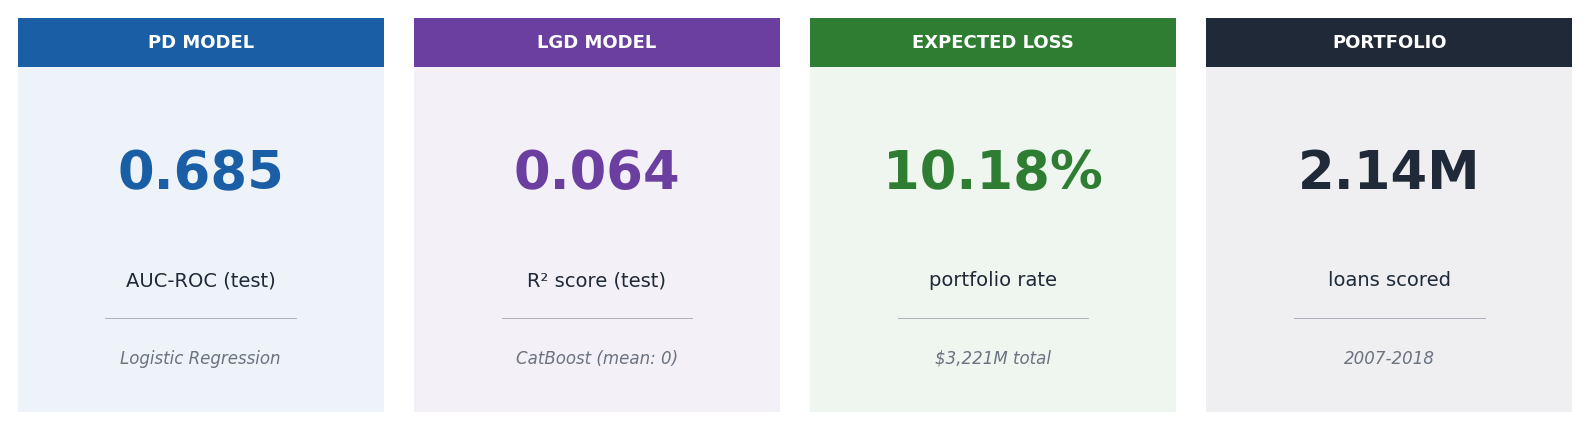

In [16]:
# Test metrics of the selected PD and LGD models (selected by cross-validation in 05 and 06)
results_PD  = pd.read_csv("models/PD_model_comparison.csv", index_col="model")
results_LGD = pd.read_csv("models/LGD_model_comparison.csv", index_col="model")
best_PD, best_LGD = results_PD["cv_auc"].idxmax(), results_LGD["cv_rmse"].idxmin()

years = f"{int(df_master_features['issue_date_year'].min())}-{int(df_master_features['issue_date_year'].max())}"
plot_key_metrics(
    pd_auc=results_PD.loc[best_PD, "auc"], pd_model=best_PD,
    lgd_r2=results_LGD.loc[best_LGD, "r2"], lgd_model=best_LGD,
    el_rate=el_rate, el_total=expected_loss,
    n_loans=len(df_master_features), years=years,
)
plt.show()

Saved assets\pipeline.png


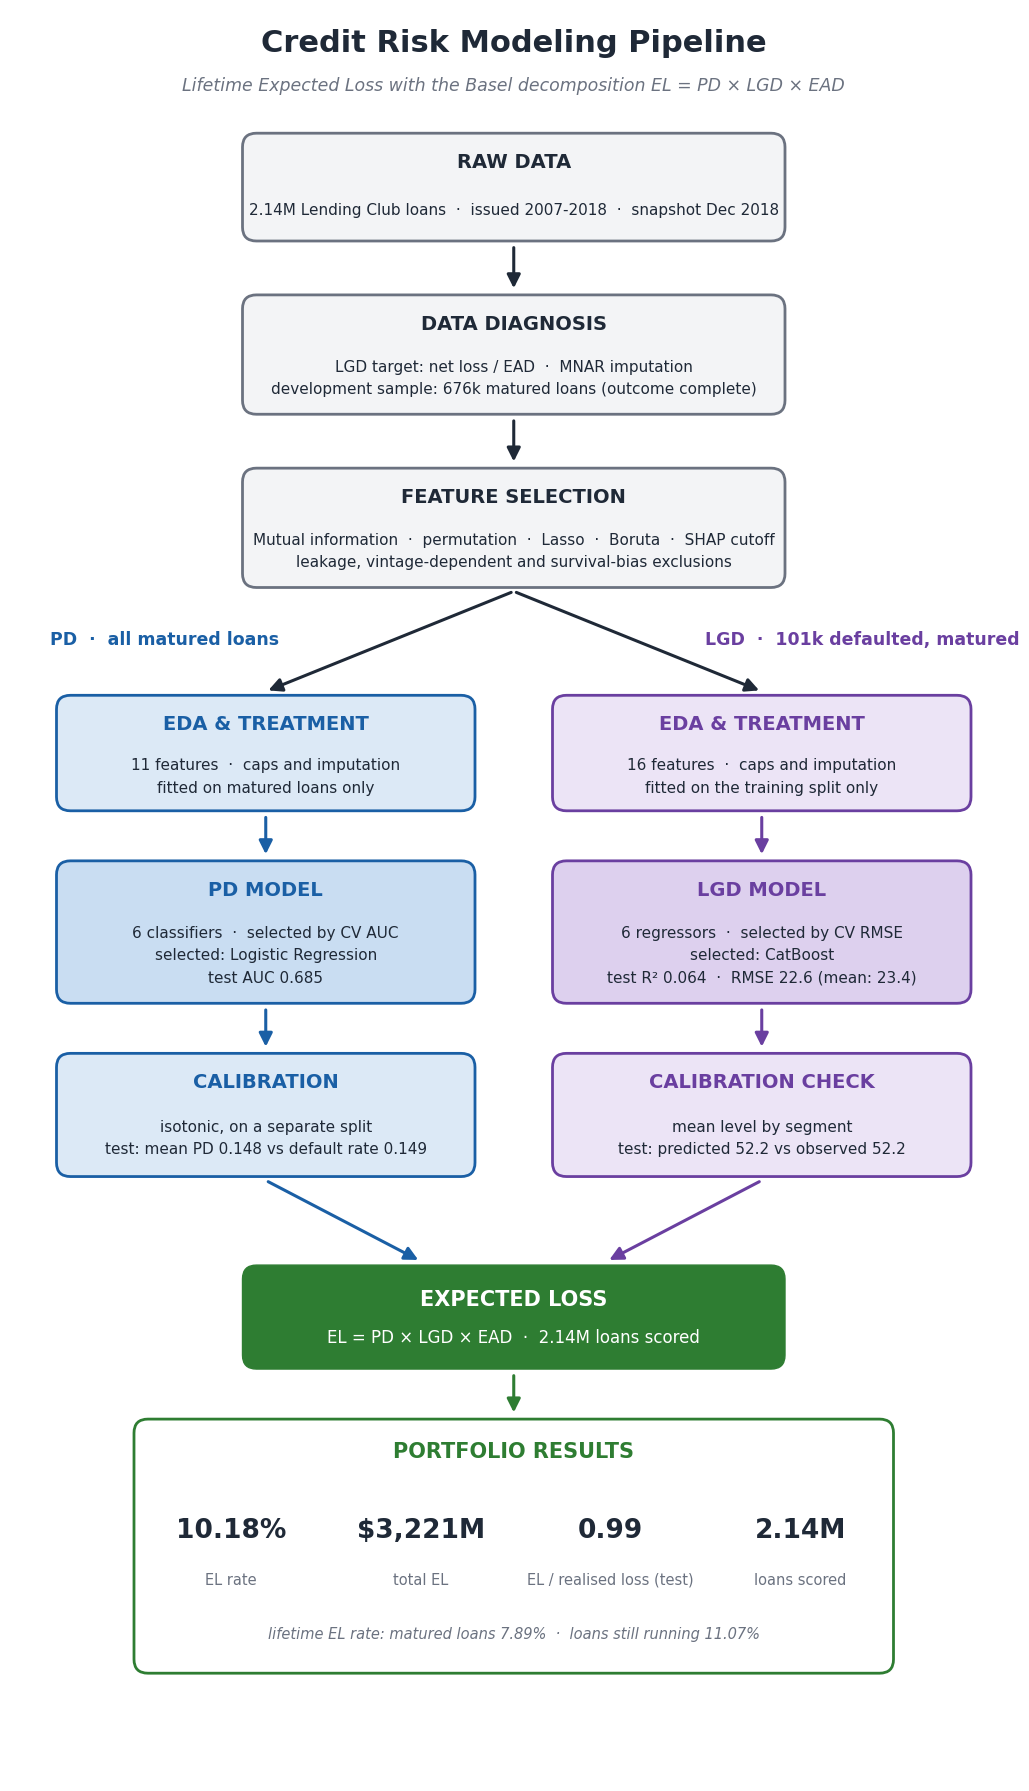

In [17]:
# Pipeline overview for the README, with the numbers of this run.
# The LGD test split is rebuilt with the same call as in 06_training_lgd.
with open("data/processed/checkpoint_df_LGD_training.pkl", "rb") as f:
    lgd_index = pickle.load(f)["df_LGD_clean"].index
idx_train_LGD, idx_test_LGD = train_test_split(lgd_index, test_size=0.2, random_state=42)
y_train_LGD = df_master_features.loc[idx_train_LGD, "Target_Variable_Loss"]
y_test_LGD = df_master_features.loc[idx_test_LGD, "Target_Variable_Loss"]

n_features = {}
for model in ["PD", "LGD"]:
    n_features[model] = 0
    for kind in ["num", "cat"]:
        with open(f"data/processed/features_{model}_{kind}_for_training.pkl", "rb") as f:
            n_features[model] += len(pickle.load(f))

max_year = int(df_master_features["issue_date_year"].max())
month_col = df_master_features.loc[df_master_features["issue_date_year"] == max_year, "issue_date_month"]
if not pd.api.types.is_numeric_dtype(month_col):
    month_col = pd.to_datetime(month_col.astype(str).str[:3], format="%b").dt.month
snapshot = pd.Timestamp(year=max_year, month=int(month_col.max()), day=1).strftime("%b %Y")

plot_pipeline({
    "n_loans": len(df_master_features), "years": years, "snapshot": snapshot,
    "n_matured": int(matured.sum()), "n_defaults": int((matured & mask_default).sum()),
    "n_features_pd": n_features["PD"], "n_features_lgd": n_features["LGD"],
    "pd_model": best_PD, "pd_auc": results_PD.loc[best_PD, "auc"],
    "pd_mean_test": df_master_features.loc[test, "PD"].mean(),
    "default_rate_test": df_master_features.loc[test, "Target_Variable_Default"].mean(),
    "lgd_model": best_LGD, "lgd_r2": results_LGD.loc[best_LGD, "r2"],
    "lgd_rmse": results_LGD.loc[best_LGD, "rmse"],
    "lgd_baseline_rmse": float(np.sqrt(((y_test_LGD - y_train_LGD.mean()) ** 2).mean())),
    "lgd_pred_test": df_master_features.loc[idx_test_LGD, "LGD"].mean(),
    "lgd_obs_test": y_test_LGD.mean(),
    "el_rate": el_rate, "el_total": expected_loss, "el_ratio_test": expected_loss_test / observed_loss_test,
    "el_rate_matured": by_maturity.loc["matured", "EL_rate_pct"],
    "el_rate_running": by_maturity.loc["not matured", "EL_rate_pct"],
})
plt.show()

## 5. Save Final Portfolio

In [18]:
os.makedirs("data/processed", exist_ok=True)

with open("data/processed/portfolio_with_EL.pkl", "wb") as f:
    pickle.dump({"df_master_features": df_master_features}, f)

print(f"Final portfolio saved. Shape: {df_master_features.shape}")
print(f"Columns: {df_master_features.columns.tolist()}")

Final portfolio saved. Shape: (2139643, 60)
Columns: ['Target_Variable_Default', 'Target_Variable_Loss', 'EAD', 'interest_rate', 'monthly_payment', 'grade', 'emp_title', 'emp_length', 'home_ownership_status', 'annual_income', 'verification_status', 'loan_purpose', 'addr_state', 'dept_paym_income_ratio', 'num_30+_delinq_in_2yrs', 'num_inq_in_6mths', 'num_open_credit_lines', 'num_derogatory_pub_rec', 'total_credit_revolving_bal', 'used_credit_share', 'tot_num_credit_lines', 'initial_list_status', 'remaining_princ_for_tot_amnt_fund', 'paym_rec_for_tot_amnt_fund', 'princ_rec', 'interest_rec', 'num_open_trades_in_6mths', 'num_installment_acc_op_in_12mths', 'num_installment_acc_op_in_24mths', 'num_rev_trades_op_in_12mths', 'num_rev_trades_op_in_24mths', 'max_bal_owed', 'bal_to_cred_lim', 'num_inq', 'num_inq_in_12mths', 'loan_term_months', 'issue_date_month', 'issue_date_year', 'region_code', 'earliest_cr_line_month', 'earliest_cr_line_year', 'is_matured', 'has_late_fees_PD', 'late_fees_rec_L